# Lab 06: Gradient Descent and SGD

**Course:** Deep Learning for Computer Vision — 2026  
**Lecture connection:** Lecture 4A

In this lab, you will compare random search with gradient-based
optimization, implement minibatch sampling, and train a linear
classifier with stochastic gradient descent.


## 1. Setup

Keep the notebook, `linear_classifier.py`, and the `dlcv2026`
directory together. Run this cell again after editing
`linear_classifier.py`.


In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
import torch

candidate_dirs = [
    Path.cwd(),
    Path.cwd() / "Labs" / "Lab06",
    Path.cwd() / "Lab06",
    Path.cwd()
    / "Deep-Learning-for-Computer-Vision"
    / "Labs"
    / "Lab06",
]
lab_dir = next(
    (
        path.resolve()
        for path in candidate_dirs
        if (path / "linear_classifier.py").is_file()
        and (path / "dlcv2026").is_dir()
    ),
    None,
)
if lab_dir is None:
    raise FileNotFoundError(
        "Could not find the Lab06 support files. Keep linear_classifier.py "
        "and the dlcv2026 folder together with the notebook."
    )

if str(lab_dir) not in sys.path:
    sys.path.insert(0, str(lab_dir))
for module_name in tuple(sys.modules):
    if (
        module_name == "linear_classifier"
        or module_name == "dlcv2026"
        or module_name.startswith("dlcv2026.")
    ):
        del sys.modules[module_name]

import dlcv2026
import linear_classifier

importlib.reload(linear_classifier)

torch.set_default_dtype(torch.float64)
torch.manual_seed(0)

print("PyTorch:", torch.__version__)
print("Lab directory:", lab_dir)
print("Implementation:", Path(linear_classifier.__file__).resolve())


PyTorch: 2.14.0+cu126
Lab directory: D:\BRICS\dl4cv\Lab06
Implementation: D:\BRICS\dl4cv\Lab06\linear_classifier.py


## 2. Check the loss gradient

The optimizer receives an analytic gradient from the SVM loss. A
centered finite-difference check verifies a few entries before we
use that gradient for training.


In [2]:
importlib.reload(linear_classifier)

torch.manual_seed(4)
X_check = torch.randn(8, 5)
W_check = 0.05 * torch.randn(5, 4)
y_check = torch.tensor([0, 1, 2, 3, 0, 2, 1, 3])

_, analytic_gradient = linear_classifier.svm_loss_vectorized(
    W_check, X_check, y_check, reg=0.02
)
loss_at = lambda weights: linear_classifier.svm_loss_vectorized(
    weights, X_check, y_check, reg=0.02
)[0]
errors = dlcv2026.grad_check_sparse(
    loss_at,
    W_check,
    analytic_gradient,
    num_checks=6,
    h=1e-6,
)
print("maximum relative error:", max(errors))
assert max(errors) < 1e-5


index=(3, 3) numerical=+2.8415038e-01 analytic=+2.8415038e-01 relative_error=5.954e-10
index=(0, 2) numerical=+1.5430930e-02 analytic=+1.5430930e-02 relative_error=1.565e-09
index=(4, 3) numerical=+1.1111276e-01 analytic=+1.1111277e-01 relative_error=1.282e-09
index=(3, 2) numerical=+1.4056491e-01 analytic=+1.4056491e-01 relative_error=8.732e-11
index=(3, 2) numerical=+1.4056491e-01 analytic=+1.4056491e-01 relative_error=8.732e-11
index=(4, 1) numerical=-2.0511740e-01 analytic=-2.0511740e-01 relative_error=5.849e-10
maximum relative error: 1.5645921637886402e-09


## 3. Random search baseline

The cell below evaluates 20 independently sampled weight matrices.
It keeps the one with the smallest training loss. Gradient descent
will instead use the local slope to choose every update.


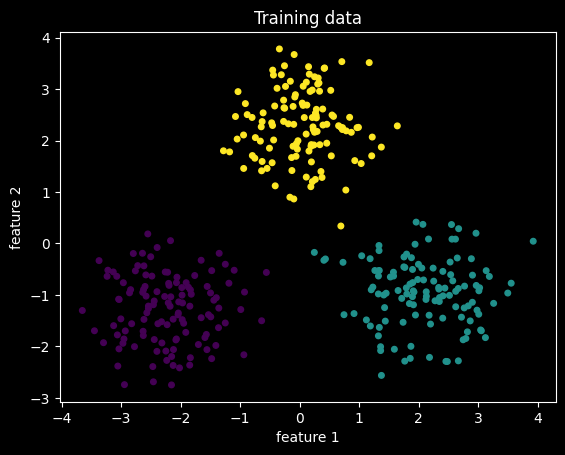

best random-search loss: 0.4844
random-search validation accuracy: 78.33%


In [3]:
data = dlcv2026.make_toy_classification(seed=11)

plt.scatter(
    data["X_train"][:, 0],
    data["X_train"][:, 1],
    c=data["y_train"],
    cmap="viridis",
    s=16,
)
plt.title("Training data")
plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.show()

generator = torch.Generator().manual_seed(4)
best_loss = float("inf")
best_random_W = None
for _ in range(20):
    candidate_W = 0.5 * torch.randn(3, 3, generator=generator)
    candidate_loss, _ = linear_classifier.svm_loss_vectorized(
        candidate_W,
        data["X_train"],
        data["y_train"],
        reg=1e-3,
    )
    if float(candidate_loss) < best_loss:
        best_loss = float(candidate_loss)
        best_random_W = candidate_W

random_predictions = linear_classifier.predict_linear_classifier(
    best_random_W, data["X_val"]
)
random_accuracy = linear_classifier.accuracy(
    random_predictions, data["y_val"]
)
print(f"best random-search loss: {best_loss:.4f}")
print(f"random-search validation accuracy: {100 * random_accuracy:.2f}%")


## 4. Exercise 1 — Sample a minibatch

Complete `sample_batch` in `linear_classifier.py`. Draw indices
with replacement using `torch.randint`, and pass the supplied
generator to make the test reproducible.


In [4]:
importlib.reload(linear_classifier)

X_index = torch.arange(30, dtype=torch.float64).reshape(10, 3)
y_index = torch.arange(10, dtype=torch.int64)
generator = torch.Generator().manual_seed(3)
X_batch, y_batch = linear_classifier.sample_batch(
    X_index, y_index, batch_size=6, generator=generator
)

print("batch labels:", y_batch.tolist())
assert X_batch.shape == (6, 3)
assert y_batch.tolist() == [6, 8, 7, 7, 0, 0]
assert torch.equal(X_batch[:, 0] / 3, y_batch.to(torch.float64))


batch labels: [6, 8, 7, 7, 0, 0]


## 5. Exercise 2 — Apply the SGD update

Complete the update inside `train_linear_classifier`:

$$
W \leftarrow W - \eta\nabla_W L.
$$

Here, $\eta$ is the learning rate and the gradient is computed on
the current minibatch.


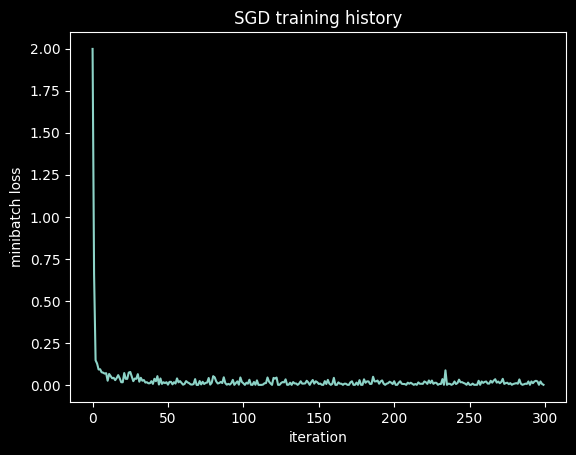

early mean loss: 0.1916
late mean loss: 0.0130
validation accuracy: 100.00%


In [5]:
importlib.reload(linear_classifier)

W_sgd, minibatch_history = (
    linear_classifier.train_linear_classifier(
        linear_classifier.svm_loss_vectorized,
        data["X_train"],
        data["y_train"],
        learning_rate=0.08,
        reg=1e-3,
        num_iters=300,
        batch_size=64,
        seed=5,
    )
)

plt.plot(minibatch_history)
plt.xlabel("iteration")
plt.ylabel("minibatch loss")
plt.title("SGD training history")
plt.show()

val_predictions = linear_classifier.predict_linear_classifier(
    W_sgd, data["X_val"]
)
val_accuracy = linear_classifier.accuracy(
    val_predictions, data["y_val"]
)
early_loss = sum(minibatch_history[:20]) / 20
late_loss = sum(minibatch_history[-20:]) / 20
print(f"early mean loss: {early_loss:.4f}")
print(f"late mean loss: {late_loss:.4f}")
print(f"validation accuracy: {100 * val_accuracy:.2f}%")
assert late_loss < early_loss
assert val_accuracy > 0.90


## 6. Full-batch gradient descent and minibatch SGD

Full-batch gradient descent uses every training example for each
update. Its curve is smooth but each step uses more data. Minibatch
SGD uses fewer examples per step, so its loss is noisier.


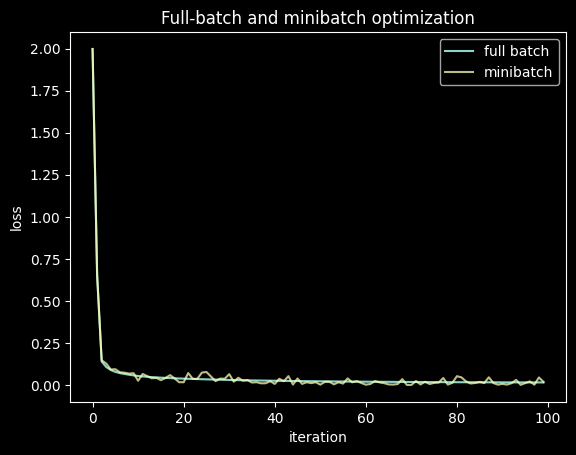

In [6]:
generator = torch.Generator().manual_seed(5)
W_full = 1e-3 * torch.randn(3, 3, generator=generator)
full_batch_history = []
for _ in range(100):
    loss, gradient = linear_classifier.svm_loss_vectorized(
        W_full,
        data["X_train"],
        data["y_train"],
        reg=1e-3,
    )
    full_batch_history.append(float(loss))
    W_full = W_full - 0.08 * gradient

plt.plot(full_batch_history, label="full batch")
plt.plot(minibatch_history[:100], alpha=0.75, label="minibatch")
plt.xlabel("iteration")
plt.ylabel("loss")
plt.title("Full-batch and minibatch optimization")
plt.legend()
plt.show()


## 7. Learning-rate experiment

Run the same training procedure with four learning rates. Compare
how quickly the curves fall and how much they fluctuate.


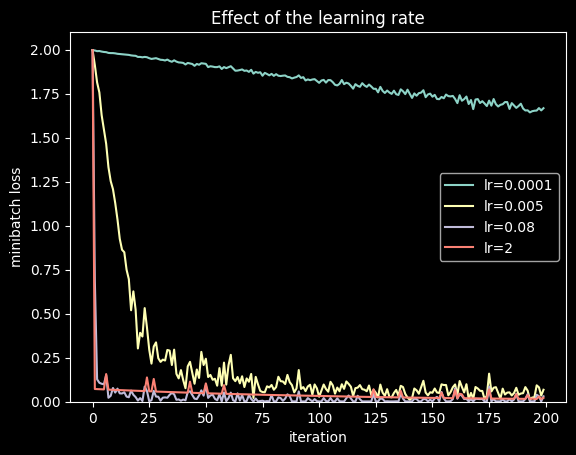

In [7]:
learning_rates = [1e-4, 5e-3, 8e-2, 2.0]
for learning_rate in learning_rates:
    _, history = linear_classifier.train_linear_classifier(
        linear_classifier.svm_loss_vectorized,
        data["X_train"],
        data["y_train"],
        learning_rate=learning_rate,
        reg=1e-3,
        num_iters=200,
        batch_size=32,
        seed=5,
    )
    plt.plot(history, label=f"lr={learning_rate:g}")

plt.ylim(0, 2.1)
plt.xlabel("iteration")
plt.ylabel("minibatch loss")
plt.title("Effect of the learning rate")
plt.legend()
plt.show()


## 8. Wrap-up

Answer briefly in a new Markdown cell:

1. Why does the negative gradient point toward the steepest local decrease? <br>
The gradient shows the direction in which the loss grows fastest. If you move a tiny step in some direction, the loss changes by (gradient · direction), which is largest when the direction matches the gradient. So going the opposite way, along the negative gradient, makes the loss drop the fastest.
2. Why is a minibatch loss curve noisier than a full-batch curve? <br>
A minibatch uses only a few randomly picked examples, so its loss and gradient are just a rough estimate of the true ones. Each batch is different, so the values jump around from step to step. Full-batch uses all the data every time, so there is no randomness and the curve is smooth.
3. What can happen when the learning rate is too small or too large? <br>
If it is too small (e.g. 1e-4), each step is tiny, so the loss goes down very slowly and barely changes in 200 iterations. If it is too large (e.g. 2.0), the steps overshoot the minimum, so the loss bounces around, stays high, or can even grow and blow up.
